# CircuitTrim
### Quantum circuit simplifier
**Author: Swayam Shakya** · MIT License

Remove adjacent inverse gates and check that the circuit still performs the same operation.

**Before opening this notebook**, run `python -m pip install -e ".[notebook]"` in the extracted project folder. Then run `python -m jupyterlab` and open this notebook. Choose a Python kernel from that environment and run the cells in order.

The core runs locally, without a cloud account or quantum hardware. The interactive panel uses Jupyter widgets. This notebook supports 1–4 qubits and at most 120 gates.

In [1]:
# Finding the extracted project folder
from pathlib import Path
import sys

root = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / "circuittrim" / "core.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Open this notebook from the extracted CircuitTrim project folder.")
sys.path.insert(0, str(root))

# Importing the circuit tools
from circuittrim import Circuit, parse_circuit, probabilities, simplify, verify
from circuittrim.render import comparison_svg, report_html
from IPython.display import SVG, display

## 1. Start with a small circuit
Write one gate per line. `H 0` applies a Hadamard gate to qubit zero. `CX 0 1` uses q0 as the control and q1 as the target. Semicolons, `q0` notation, commas, and `#` comments are also accepted.

This example contains redundant pairs around a Bell-state preparation.

In [2]:
# Loading the example circuit
source = (root / "examples" / "bell.ct").read_text(encoding="utf-8")
original = parse_circuit(source, n_qubits=2)
print(original.to_text())

H 0
X 1
X 1
S 0
SDG 0
H 0
H 0
CX 0 1
Z 1
Z 1
T 0
TDG 0


## 2. Remove redundant pairs
H, X, Y, Z, CX, CZ, and SWAP undo themselves. S/SDG and T/TDG undo each other. Each pair must act on the same qubits, and CX must keep the same control direction.

The simplifier reads left to right using a stack. Removing one pair may expose another. It does not move gates past unrelated instructions or claim to find the smallest possible circuit.

In [3]:
# Simplifying the circuit
result = simplify(original)
print(f"Gates: {len(original.gates)} -> {len(result.simplified.gates)}")
print(f"Reduction: {result.reduction_percent:.1f}%")
print("\nRemaining instructions:")
print(result.simplified.to_text() or "Identity (no gates)")

# Showing each removed pair
for step in result.cancellations:
    print(f"Positions {step.left_index + 1}, {step.right_index + 1}: {step.reason}")

Gates: 12 -> 2
Reduction: 83.3%

Remaining instructions:
H 0
CX 0 1
Positions 2, 3: X 1 + X 1 = identity
Positions 4, 5: S 0 + SDG 0 = identity
Positions 1, 6: H 0 + H 0 = identity
Positions 9, 10: Z 1 + Z 1 = identity
Positions 11, 12: T 0 + TDG 0 = identity


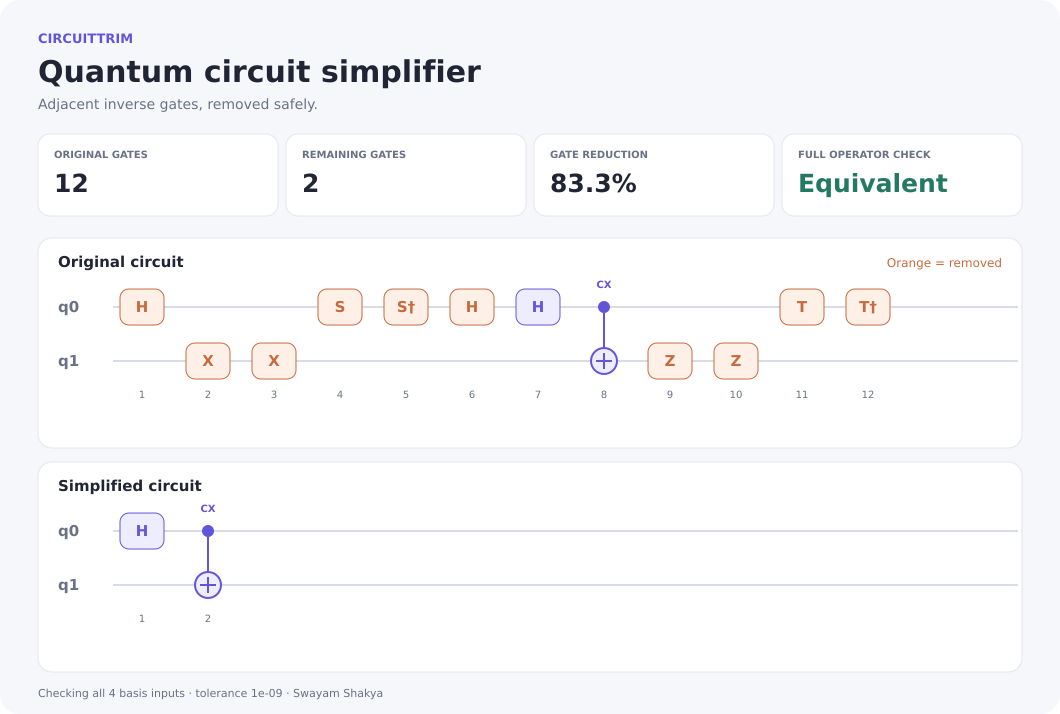

In [4]:
# Drawing the original and simplified circuits
display(SVG(comparison_svg(result)))

## 3. Check the full operation
Comparing probabilities for the all-zero input is not enough. Two circuits can produce the same probabilities and still change phases differently.

The verifier checks the complex output amplitudes for every computational basis input. Those outputs are the columns of the circuit's operator, so this also checks its action on superpositions. Equality is strict within a numerical tolerance of `1e-9`; even a difference consisting only of a global phase is reported.

In [5]:
# Checking every basis input
check = verify(original, result.simplified)
print("Equivalent:", check.equivalent)
print("Inputs checked:", check.inputs_checked)
print(f"Maximum amplitude difference: {check.max_error:.3e}")
assert check.equivalent

# Comparing probabilities from the all-zero state
before = probabilities(original)
after = probabilities(result.simplified)
for state in before:
    print(f"|{state}>  original={before[state]:.4f}  simplified={after[state]:.4f}")

Equivalent: True
Inputs checked: 4
Maximum amplitude difference: 1.110e-16
|00>  original=0.5000  simplified=0.5000
|01>  original=0.0000  simplified=0.0000
|10>  original=0.0000  simplified=0.0000
|11>  original=0.5000  simplified=0.5000


Bit strings read **q(n−1)…q0**. Qubit zero is the least significant bit, but appears on the top wire in drawings. The Bell example has probability 0.5 for `00` and 0.5 for `11`. These are simulated probabilities, not hardware measurements.

In [6]:
# Demonstrating why probabilities alone are insufficient
phase_flip = parse_circuit("Z 0", n_qubits=1)
identity = Circuit(1)
print("Same probabilities from |0>:", probabilities(phase_flip) == probabilities(identity))
print("Same full operation:", verify(phase_flip, identity).equivalent)

Same probabilities from |0>: True
Same full operation: False


## 4. Try the interactive workbench
Choose a preset or edit the instructions, select the qubit count, and click **Simplify & verify**. Editing the input clears the old result to avoid confusing it with a new result. The download link saves a self-contained HTML report.

If controls appear as plain text, use JupyterLab 4 with the notebook extras installed in the same Python environment. Restart the kernel and run the cells again. The cells above work without interactive widgets.

In [7]:
# Opening the interactive circuit editor
from circuittrim.workbench import launch
workbench = launch()

Run this cell to open the interactive workbench.


## 5. Export a report
This exports the fixed Bell example above. To export your most recent interactive result instead, replace `result` with `workbench.result` after a successful run.

In [8]:
# Saving a report that opens directly in a browser
report_path = root / "reports" / "notebook-report.html"
report_path.parent.mkdir(exist_ok=True)
report_path.write_text(report_html(result), encoding="utf-8")
print("Saved reports/notebook-report.html")

Saved reports/notebook-report.html


## Scope and next steps
- This is a small educational optimizer for ideal unitary circuits.
- Measurement, reset, noise, arbitrary rotations, and hardware execution are outside this version.
- Fewer gates here means fewer listed instructions, not a measured hardware speedup.
- The simplifier runs in O(g) time. Full verification costs O(g × 4ⁿ), which is why the workbench limits circuit size.

Try `H 0; X 0; X 0; H 0` to see cascading cancellation, or `X 0; H 1; X 0` to see a pair deliberately left unchanged because the instructions are not adjacent.

See `docs/ALGORITHM.md` for the rules and `docs/TESTING.md` for test coverage.